# Experiment 4: Statistical Inference, Estimation and Hypothesis Testing
**Aim:** To perform statistical inference, estimation and hypothesis testing on real-world data.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
plt.rcParams["figure.dpi"] = 100
sns.set_style("whitegrid")
COLS = ["Pregnancies","Glucose","BloodPressure","SkinThickness",
        "Insulin","BMI","DiabetesPedigreeFunction","Age","Outcome"]
df = pd.read_csv("pima-indians-diabetes.csv", names=COLS)
print("Dataset shape:", df.shape)
df.head()
from scipy import stats

Dataset shape: (768, 9)


In [2]:
# 95% confidence interval for the population mean Glucose (t-distribution)
g = df["Glucose"]
n = len(g); mean, se = g.mean(), stats.sem(g)
ci = stats.t.interval(0.95, n-1, loc=mean, scale=se)
print(f"Mean Glucose = {mean:.2f}")
print(f"95% CI for population mean Glucose: ({ci[0]:.2f}, {ci[1]:.2f})")

Mean Glucose = 120.89
95% CI for population mean Glucose: (118.63, 123.16)


In [3]:
# Two-sample t-test: is mean Glucose different for diabetic vs non-diabetic?
g1 = df[df.Outcome==1]["Glucose"]; g0 = df[df.Outcome==0]["Glucose"]
t_stat, p_val = stats.ttest_ind(g1, g0, equal_var=False)
print(f"Mean Glucose (diabetic)     = {g1.mean():.2f}")
print(f"Mean Glucose (non-diabetic) = {g0.mean():.2f}")
print(f"t-statistic = {t_stat:.3f}, p-value = {p_val:.3e}")
print("Decision:", "Reject H0 - significant difference" if p_val < 0.05 else "Fail to reject H0")

Mean Glucose (diabetic)     = 141.26
Mean Glucose (non-diabetic) = 109.98
t-statistic = 13.752, p-value = 2.644e-36
Decision: Reject H0 - significant difference


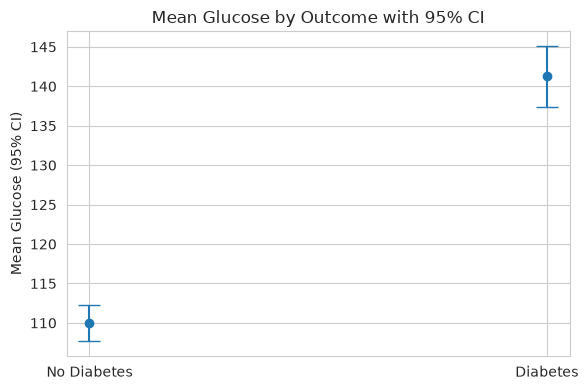

In [4]:
# Visualize the two groups with their means and 95% CIs
means = [g0.mean(), g1.mean()]
cis = [stats.t.interval(0.95, len(g0)-1, loc=means[0], scale=stats.sem(g0)),
       stats.t.interval(0.95, len(g1)-1, loc=means[1], scale=stats.sem(g1))]
plt.figure(figsize=(6,4))
plt.errorbar(["No Diabetes","Diabetes"], means,
             yerr=[means[0]-cis[0][0], cis[1][1]-means[1]], fmt="o", capsize=8)
plt.ylabel("Mean Glucose (95% CI)"); plt.title("Mean Glucose by Outcome with 95% CI")
plt.tight_layout(); plt.savefig("images/fig1_means_ci.png", dpi=130, bbox_inches="tight"); plt.show()

## Key Observations
- The 95% confidence interval gives a reliable range for the true population mean Glucose.
- The t-test overwhelmingly rejects the null hypothesis: mean Glucose differs significantly between diabetic and non-diabetic groups (p << 0.05).